# ۱۱ · بیت‌کوین؛ یک مدل خیلی ساده برای روز بعد

با چند ویژگی ضروری و یک مدل Dense کوچک، بازده روز بعد را پیش‌بینی و به قیمت تبدیل می‌کنیم.
این نسخه از درس ۰۲ کوتاه‌تر است و همان دادهٔ واقعی تاریخی همراه بسته را مصرف می‌کند.

**روش مطالعه:** سلول‌ها را از بالا به پایین اجرا کنید. هر بخش یک مفهوم کوچک و یک مثال دارد.
پیش‌نیاز فقط آشنایی مقدماتی با پایتون و لیست است. خروجی‌های فایل از اجرای واقعی کدها ذخیره شده‌اند.
این درس برای اجرا روی CPU نوشته شده است.

<style>
.jp-MarkdownOutput,.text_cell_render {direction:rtl;text-align:right;font-family:Tahoma,Arial,sans-serif;line-height:1.9}
.jp-MarkdownOutput pre,.text_cell_render pre,.jp-CodeCell,.jp-OutputArea-output {direction:ltr;text-align:left}
mjx-container,.MathJax {direction:ltr} table {direction:ltr}
</style>

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import numpy as np
import tensorflow as tf
import torch
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)

print('NumPy:', np.__version__)
print('TensorFlow:', tf.__version__)
print('PyTorch:', torch.__version__)

C:\Program Files\Python311\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


NumPy: 2.2.6
TensorFlow: 2.20.0
PyTorch: 2.9.1+cpu


## ۱. داده و زمان پیش‌بینی

پس از بسته‌شدن روز t، از اطلاعات تا همان روز برای پیش‌بینی Close روز t+1 استفاده می‌کنیم.
دادهٔ همراه بسته BTCUSDT بایننس در بازهٔ ۲۰۲۰ تا پایان ۲۰۲۴ است؛ واحد قیمت USDT است.
«روز بعد» در خروجی، روز بعد انتهای همین بازه است. کد دریافت BTC-USD از yfinance هم در سلول بعد قرار دارد.

In [2]:
from pathlib import Path
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

root=Path.cwd()
if root.name=='notebooks': root=root.parent
USE_YFINANCE=False
if USE_YFINANCE:
    import yfinance as yf
    prices=yf.download('BTC-USD',start='2020-01-01',end='2025-01-01',
        auto_adjust=False,multi_level_index=False,progress=False,threads=False)
    if prices is None or prices.empty: raise RuntimeError('Yahoo returned no data. Use the bundled snapshot or retry later.')
    source,unit='Yahoo BTC-USD','USD'
else:
    prices=pd.read_csv(root/'data'/'BTCUSDT_binance_2020_2024.csv',index_col='Date',parse_dates=True)
    source,unit='Binance BTCUSDT','USDT'
prices=prices.sort_index()
assert prices.index.is_unique and not prices[['Close','Volume']].isna().any().any()
assert (prices.index.to_series().diff().dropna()==pd.Timedelta(days=1)).all()
print(source,unit,prices.shape)
display(prices[['Close','Volume']].tail())

Binance BTCUSDT USDT (1827, 5)


,Close,Volume
Date,,
2024-12-27,94299.03,26501.26429
2024-12-28,95300.00,8385.89290
2024-12-29,93738.20,13576.00578
2024-12-30,92792.05,27619.42250
2024-12-31,93576.00,19612.03389


## ۲. پنج ویژگی ساده

$$r_t=\log(P_t/P_{t-1}),\quad volatility_t=std(r_{t-6},...,r_t).$$

۱. **log return:** تغییر نسبی قیمت در یک روز، به شکل لگاریتمی.

۲. **volatility هفت‌روزه:** اندازهٔ نوسان اخیر بازده‌ها.

۳. **فاصله از میانگین هفت‌روزه:** قیمت تقسیم بر میانگین گذشته، منهای یک.

۴. **momentum هفت‌روزه:** بازده لگاریتمی قیمت نسبت به هفت روز قبل.

۵. **تغییر لگاریتمی حجم:** اطلاعاتی از تغییر فعالیت معامله.

دو ویژگی sin/cos روز هفته نیز اضافه می‌کنیم تا مدل بتواند الگوی هفتگی احتمالی را بیازماید؛ وجود آن‌ها اثبات فصل‌مندی نیست.
همهٔ پنجره‌ها از گذشته تا امروز ساخته می‌شوند.

In [3]:
close=prices['Close']
returns=np.log(close).diff()
features=pd.DataFrame(index=prices.index)
features['return']=returns
features['volatility7']=returns.rolling(7).std()
features['price_to_ma7']=close/close.rolling(7).mean()-1
features['momentum7']=np.log(close/close.shift(7))
features['volume_change']=np.log(prices['Volume'].replace(0,np.nan)).diff()
features['week_sin']=np.sin(2*np.pi*features.index.dayofweek/7)
features['week_cos']=np.cos(2*np.pi*features.index.dayofweek/7)
features=features.replace([np.inf,-np.inf],np.nan).dropna()
display(features.head().round(4))

,return,volatility7,price_to_ma7,momentum7,volume_change,week_sin,week_cos
Date,,,,,,,
2020-01-08,-0.0110,0.0351,0.0643,0.1122,0.2113,0.9749,-0.2225
2020-01-09,-0.0300,0.0344,0.0165,0.1154,-0.5614,0.4339,-0.9010
2020-01-10,0.0474,0.0334,0.0492,0.1098,0.2490,-0.4339,-0.9010
2020-01-11,-0.0218,0.0361,0.0142,0.0867,-0.4078,-0.9749,-0.2225
2020-01-12,0.0204,0.0358,0.0199,0.1064,-0.3628,-0.7818,0.6235


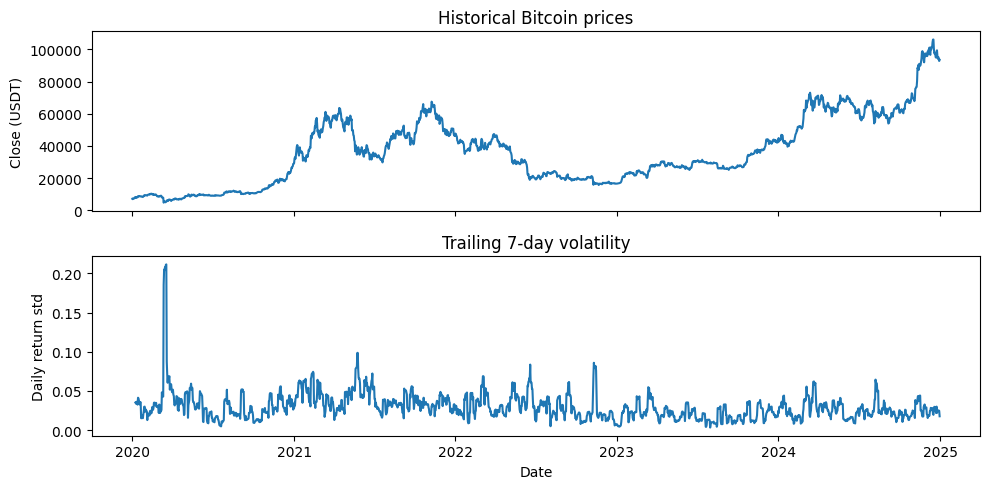

In [4]:
fig,axes=plt.subplots(2,1,figsize=(10,5),sharex=True)
axes[0].plot(close); axes[0].set(ylabel='Close ('+unit+')',title='Historical Bitcoin prices')
axes[1].plot(features['volatility7']); axes[1].set(xlabel='Date',ylabel='Daily return std',title='Trailing 7-day volatility')
plt.tight_layout(); plt.show()

## ۳. هدف و تقسیم زمانی

برای هر روز فقط همین هفت ویژگی را داریم؛ پنجرهٔ چندبعدی و Conv در این نسخه لازم نیست.
هدف، بازده **روز بعد** است:

$$y_t=\log(P_{t+1}/P_t),\qquad \hat P_{t+1}=P_t\exp(\hat y_t).$$

داده را به ترتیب زمان به ۷۰٪ train، ۱۵٪ validation و ۱۵٪ test تقسیم می‌کنیم.
مقیاس ویژگی و هدف فقط روی train یاد گرفته می‌شود.

In [5]:
target=np.log(close.shift(-1)/close).reindex(features.index)
known=target.notna()
X=features.loc[known].to_numpy()
y=target.loc[known].to_numpy().reshape(-1,1)
dates=features.index[known]
today_price=close.reindex(dates).to_numpy()
tomorrow_price=close.reindex(dates+pd.Timedelta(days=1)).to_numpy()

n=len(X); a=int(0.70*n); b=int(0.85*n)
sx=StandardScaler().fit(X[:a])
sy=StandardScaler().fit(y[:a])
X=sx.transform(X).astype('float32')
y_scaled=sy.transform(y).astype('float32')
print('Train/validation/test:',a,b-a,n-b)
print('Shapes:',X.shape,y_scaled.shape)
print('Last train origin:',dates[a-1].date(),'first validation origin:',dates[a].date())
assert dates[a-1]<dates[a]<dates[b]

Train/validation/test: 1273 273 273
Shapes: (1819, 7) (1819, 1)
Last train origin: 2023-07-03 first validation origin: 2023-07-04


## ۴. TensorFlow: مدل کوچک

ورودی هفت ویژگی، یک لایهٔ ۱۶تایی با ReLU و خروجی یک عدد است.
خروجی نهایی activation ندارد چون بازده می‌تواند مثبت یا منفی باشد. loss برابر MSE بازدهٔ استانداردشده است.

In [6]:
model_tf=tf.keras.Sequential([
    tf.keras.layers.Input((X.shape[1],)),
    tf.keras.layers.Dense(16,activation='relu'),
    tf.keras.layers.Dense(1)
])
model_tf.compile(optimizer=tf.keras.optimizers.Adam(0.001),loss='mse')
model_tf.summary()
history_tf=model_tf.fit(X[:a],y_scaled[:a],validation_data=(X[a:b],y_scaled[a:b]),
    epochs=15,batch_size=32,verbose=0,callbacks=[tf.keras.callbacks.EarlyStopping(patience=3,restore_best_weights=True)])
print('TF final validation loss:',history_tf.history['val_loss'][-1])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 145 (580.00 B)

 Trainable params: 145 (580.00 B)

 Non-trainable params: 0 (0.00 B)

TF final validation loss: 0.42560863494873047


## ۵. PyTorch: همان ساختار

در هر epoch، train وزن‌ها را تغییر می‌دهد و validation فقط برای انتخاب بهترین وزن‌ها استفاده می‌شود.
این حلقهٔ کوچک بدون ابزار کمکی پنهان نوشته شده است.

In [7]:
from torch import nn
from torch.utils.data import TensorDataset,DataLoader
import copy

model_pt=nn.Sequential(nn.Linear(X.shape[1],16),nn.ReLU(),nn.Linear(16,1))
loader=DataLoader(TensorDataset(torch.from_numpy(X[:a]),torch.from_numpy(y_scaled[:a])),batch_size=32,shuffle=True)
optimizer=torch.optim.Adam(model_pt.parameters(),lr=0.001)
loss_fn=nn.MSELoss(); val_losses=[]; best=float('inf')
for epoch in range(15):
    model_pt.train()
    for xb,yb in loader:
        optimizer.zero_grad(); loss=loss_fn(model_pt(xb),yb)
        loss.backward(); optimizer.step()
    model_pt.eval()
    with torch.no_grad(): value=loss_fn(model_pt(torch.from_numpy(X[a:b])),torch.from_numpy(y_scaled[a:b])).item()
    val_losses.append(value)
    if value<best:
        best=value; best_weights=copy.deepcopy(model_pt.state_dict())
model_pt.load_state_dict(best_weights)
print(model_pt,'\nBest Torch validation loss:',best)

Sequential(
  (0): Linear(in_features=7, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
) 
Best Torch validation loss: 0.4220770597457886


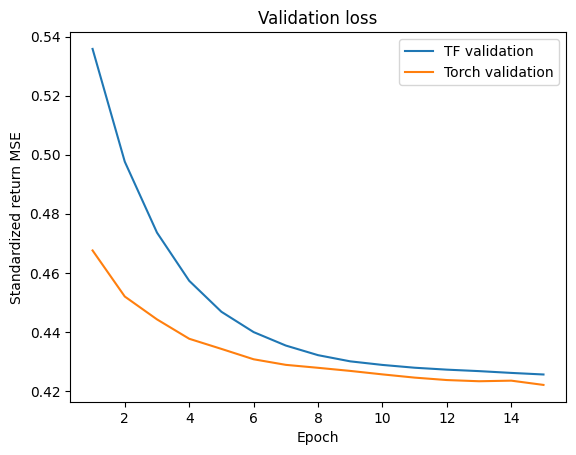

In [8]:
plt.plot(np.arange(1,len(history_tf.history['val_loss'])+1),history_tf.history['val_loss'],label='TF validation')
plt.plot(np.arange(1,len(val_losses)+1),val_losses,label='Torch validation')
plt.xlabel('Epoch'); plt.ylabel('Standardized return MSE'); plt.title('Validation loss'); plt.legend(); plt.show()

## ۶. ارزیابی با خط پایه

اگر هیچ مدلی نداشتیم، می‌توانستیم قیمت فردا را برابر قیمت امروز بگیریم. این خط پایه persistence نام دارد.
پیش‌بینی خوب باید با این خط پایه مقایسه شود؛ شبیه‌بودن منحنی قیمت به تنهایی کافی نیست.
آزمون، پیش‌بینی یک روز جلو با مشاهدهٔ واقعی هر روز است؛ پیش‌بینی بازگشتی چندماهه نیست.

,model,price_MAE,unit
0,Persistence,1324.232271,USDT
1,TF Dense,1386.611974,USDT
2,Torch Dense,1344.284918,USDT


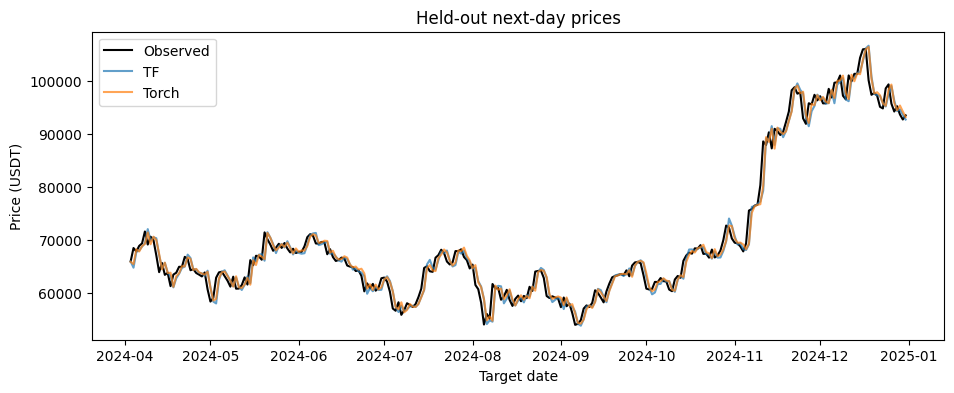

In [9]:
r_tf=sy.inverse_transform(model_tf.predict(X[b:],verbose=0)).ravel()
model_pt.eval()
with torch.no_grad(): r_pt=sy.inverse_transform(model_pt(torch.from_numpy(X[b:])).numpy()).ravel()
p_tf=today_price[b:]*np.exp(r_tf)
p_pt=today_price[b:]*np.exp(r_pt)
results=pd.DataFrame({
    'model':['Persistence','TF Dense','Torch Dense'],
    'price_MAE':[mean_absolute_error(tomorrow_price[b:],p) for p in [today_price[b:],p_tf,p_pt]]
})
results['unit']=unit
display(results)
plt.figure(figsize=(11,4))
plt.plot(dates[b:]+pd.Timedelta(days=1),tomorrow_price[b:],label='Observed',color='black')
plt.plot(dates[b:]+pd.Timedelta(days=1),p_tf,label='TF',alpha=0.7)
plt.plot(dates[b:]+pd.Timedelta(days=1),p_pt,label='Torch',alpha=0.7)
plt.xlabel('Target date'); plt.ylabel('Price ('+unit+')'); plt.title('Held-out next-day prices'); plt.legend(); plt.show()

## ۷. روز بعد آخرین سطر داده

آخرین سطر features هدف مشاهده‌شده ندارد و در آموزش یا آزمون استفاده نشده است.
آن را با scaler قبلی تبدیل می‌کنیم. این خروجی برای روز بعد انتهای بازهٔ تاریخی است.

In [10]:
latest=sx.transform(features.iloc[[-1]].to_numpy()).astype('float32')
next_tf=float(sy.inverse_transform(model_tf.predict(latest,verbose=0))[0,0])
with torch.no_grad(): next_pt=float(sy.inverse_transform(model_pt(torch.from_numpy(latest)).numpy())[0,0])
forecast=pd.DataFrame({
    'model':['TF Dense','Torch Dense'],
    'target_date':[str((features.index[-1]+pd.Timedelta(days=1)).date())]*2,
    'forecast_price':[float(close.iloc[-1])*np.exp(next_tf),float(close.iloc[-1])*np.exp(next_pt)],
    'unit':[unit]*2
})
display(forecast)
folder=root/'artifacts'; folder.mkdir(exist_ok=True)
results.to_csv(folder/'11_btc_simple_metrics.csv',index=False)
forecast.to_csv(folder/'11_btc_simple_forecast.csv',index=False)

,model,target_date,forecast_price,unit
0,TF Dense,2025-01-01,92718.667560,USDT
1,Torch Dense,2025-01-01,93469.828898,USDT


## ۸. نکته‌های ضروری

- دادهٔ زمانی را قبل از split تصادفی نکنید. درون train این مدل بدون state می‌توان batchها را shuffle کرد.
- از High/Low/Close کامل روز جاری فقط پس از پایان همان روز استفاده کنید.
- اگر مدل از persistence بدتر شد، همین نتیجه را گزارش کنید؛ زیادکردن لایه‌ها تضمین بهبود نیست.
- ویژگی روز هفته یک امکان برای آزمودن الگوست، نه اثبات seasonality.
- تبدیل exp پیش‌بینی بازده، پیش‌بینی نقطه‌ای قیمت می‌دهد؛ لزوماً امید ریاضی قیمت نیست.
- برای دادهٔ جدید، کل فرایند تقسیم و مقیاس‌کردن و آموزش باید دوباره با رعایت ترتیب زمان اجرا شود.

**تمرین:** دو ویژگی هفته را حذف کنید و فقط با validation مقایسه کنید.

## منابع رسمی


- [yfinance download](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html)
- [داده‌های عمومی بایننس](https://github.com/binance/binance-public-data)
- [جلوگیری از data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)


بازبینی منابع و اجرای این درس: ۱۶ اکتبر ۲۰۲۶.